### Normalization
- Normlaization is a technique often applied as part of data prepartion for ml. the goal of normalization is to
change the values of numeric columns in the dataset to use a common scale, without distorting differnces in the ranges of losing information.

**Type of Noralization**
- MinMaxScaler
- Mean normalization 
- max absolute 
- Robust Scaling
- 

#### MinMaxScaling

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
weight = np.random.randint(40, 100, 15)
weight

array([98, 58, 87, 41, 66, 99, 96, 50, 40, 47, 58, 42, 49, 99, 86],
      dtype=int32)

In [7]:
# Min max scaling
X_min = weight.min()
X_max = weight.max()

weight_normlized = (weight - X_min) / (X_max - X_min)
weight_normlized

array([0.98305085, 0.30508475, 0.79661017, 0.01694915, 0.44067797,
       1.        , 0.94915254, 0.16949153, 0.        , 0.11864407,
       0.30508475, 0.03389831, 0.15254237, 1.        , 0.77966102])

In [11]:
df = pd.read_csv("../data/wine_data.csv", header=None, usecols=[0,1,2])
df.columns=["Class label", "Alcohol","Malic acid"]
df.head()

,Class label,Alcohol,Malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


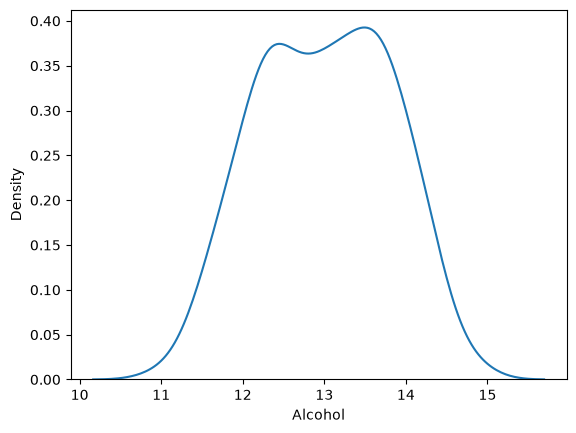

In [13]:
sns.kdeplot(df["Alcohol"]);

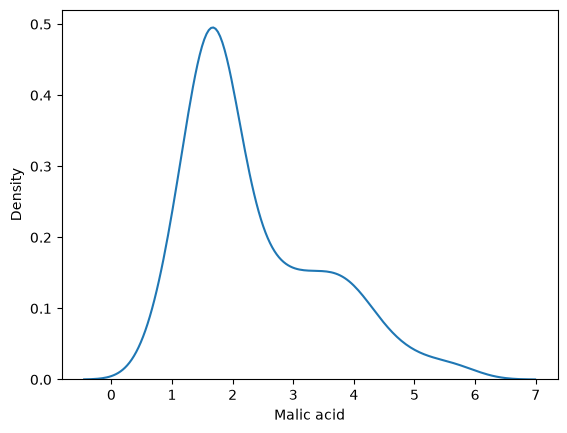

In [15]:
sns.kdeplot(df["Malic acid"]);

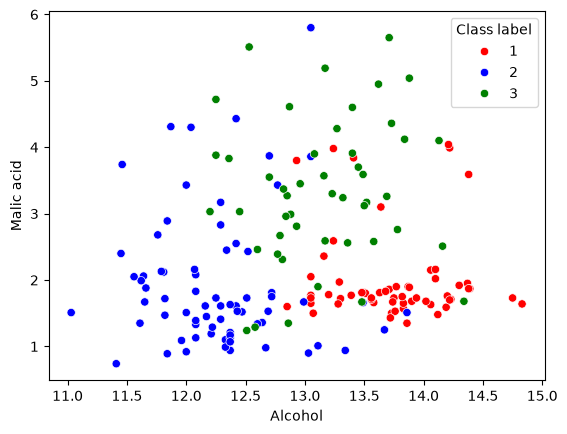

In [18]:
color_dict = { 1: "red",2: "blue",3: "green"}
sns.scatterplot(data=df,x="Alcohol",y="Malic acid",hue="Class label",palette=color_dict)
plt.show()

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop("Class label", axis=1), df["Class label"],
                                                    test_size=0.3, 
                                                    random_state=0)
X_train.shape, X_test.shape

((124, 2), (54, 2))

In [20]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

# fit the scaler to the train set, to lean the parameters
scaler.fit(X_train)

# transform train and test

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [25]:
np.round(X_train.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [24]:
np.round(X_train_scaled.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


#### Effect of scaling

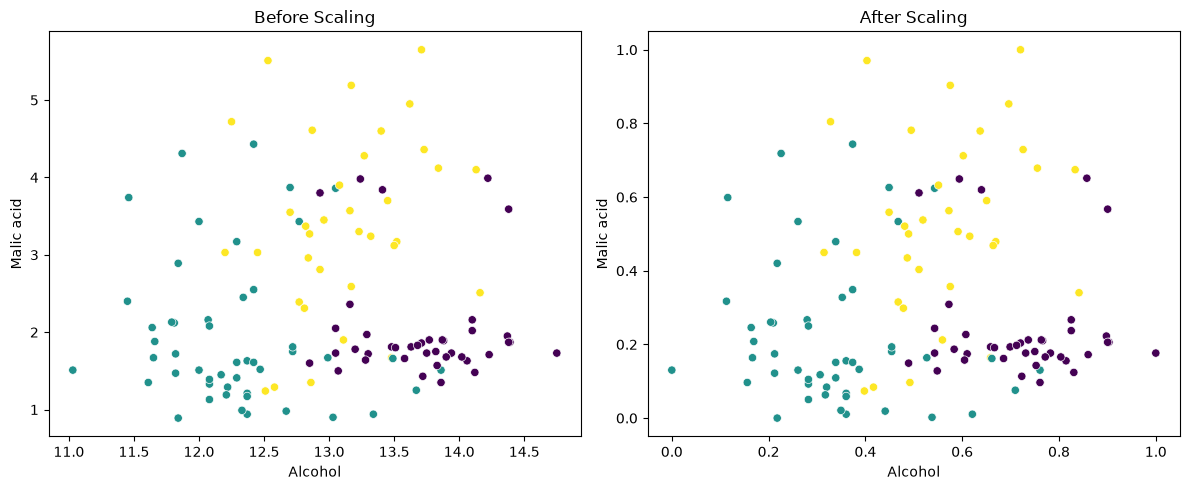

In [34]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
sns.scatterplot( data=X_train,x="Alcohol",y="Malic acid", c=y_train,ax=ax1)
ax1.set_title("Before Scaling")
sns.scatterplot( data=X_train_scaled,x="Alcohol",y="Malic acid",c=y_train,ax=ax2)
ax2.set_title("After Scaling")
plt.tight_layout()
plt.show()

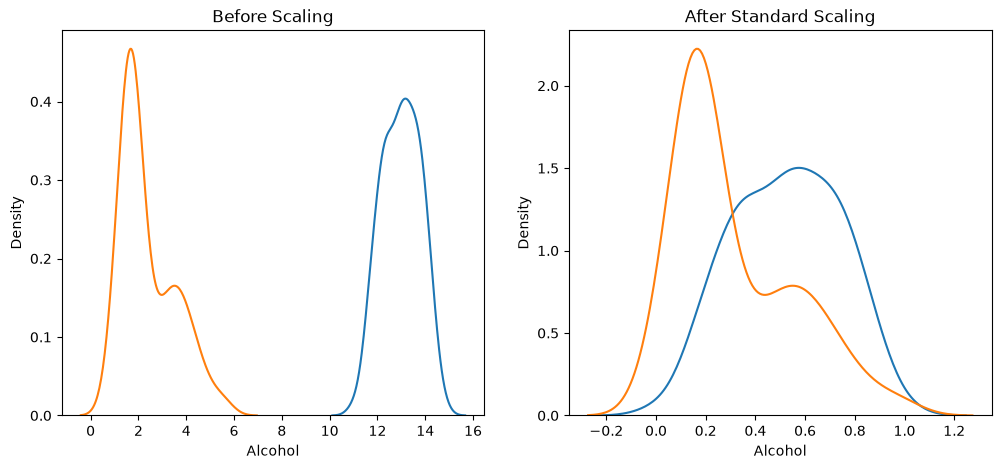

In [35]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax=ax1)
sns.kdeplot(X_train['Malic acid'], ax=ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2)
sns.kdeplot(X_train_scaled['Malic acid'], ax=ax2)
plt.show()

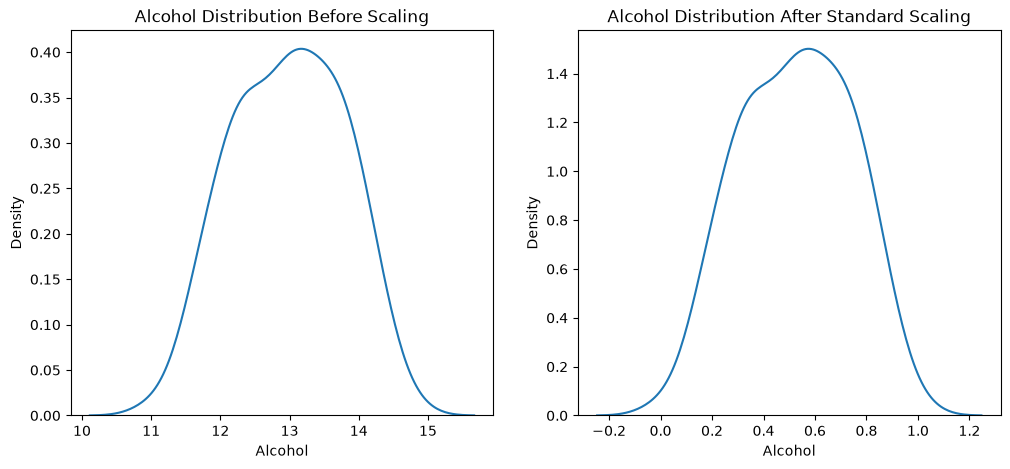

In [36]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Alcohol Distribution Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax=ax1)

# after scaling
ax2.set_title('Alcohol Distribution After Standard Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2)
plt.show()

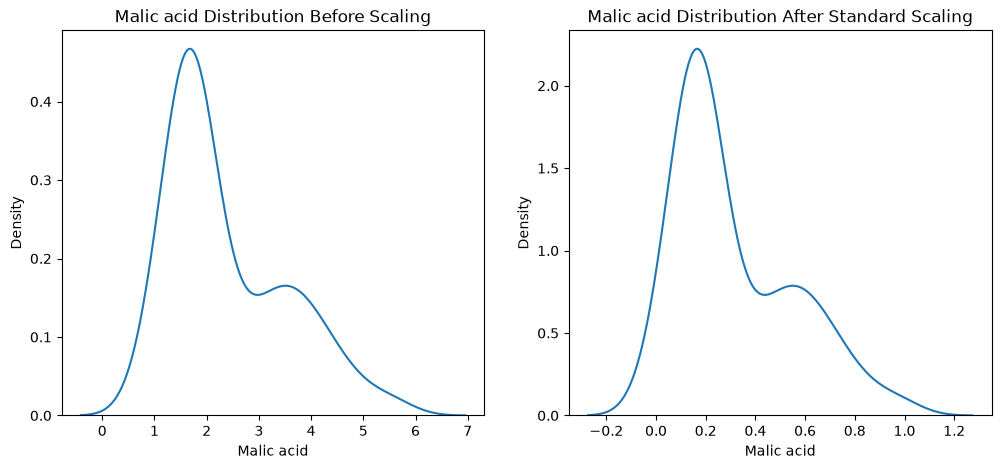

In [37]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Malic acid Distribution Before Scaling')
sns.kdeplot(X_train['Malic acid'], ax=ax1)

# after scaling
ax2.set_title('Malic acid Distribution After Standard Scaling')
sns.kdeplot(X_train_scaled['Malic acid'], ax=ax2)
plt.show()

#### mean Noralization
- mean centering

In [38]:
w = np.random.randint(10, 1000, 20)
w

array([734, 354, 323, 229, 961, 546, 206, 794, 497, 317, 490, 724,  87,
        31, 199, 791, 439, 301, 445, 975], dtype=int32)

In [39]:
w_mean = w.mean()
w_min = w.min()
w_max = w.max()
w_scaled = (w - w_mean) /( w_max - w_min)
w_scaled

array([ 0.27738347, -0.1251589 , -0.15799788, -0.25757415,  0.51784958,
        0.07823093, -0.28193856,  0.3409428 ,  0.02632415, -0.16435381,
        0.0189089 ,  0.26679025, -0.40799788, -0.46731992, -0.28935381,
        0.33776483, -0.03511653, -0.18130297, -0.02876059,  0.53268008])

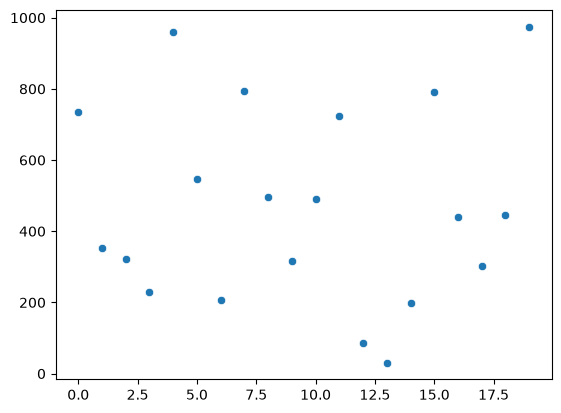

In [43]:
sns.scatterplot(w);

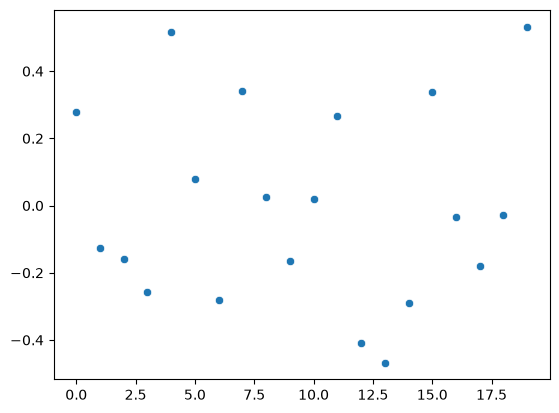

In [45]:
sns.scatterplot(w_scaled);